# 07. 보고서 차트와 수치

보고서(`reports/카페2호점_입지분석.pptx`)에 들어가는 차트 5개를 그리고, 장표에 쓰는 숫자를 한곳에 모으는 노트북입니다.

- 차트는 장표와 같은 색(네이비 팔레트)과 글꼴로 그려서 `reports/figures/`에 PNG로 저장합니다.
- 차트 크기는 장표의 그림 칸 크기에 맞췄습니다. 크기가 다르면 장표에 넣을 때 그림이 찌그러집니다.
- 장표의 숫자는 모두 이 노트북이나 04~06 노트북에서 나온 값입니다. 맨 끝에 장표별 숫자를 표로 정리했습니다.

04, 05, 06 노트북을 먼저 돌려야 합니다(`분석_대상` 뷰와 `후보_지표` 테이블을 씁니다).

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib import patheffects
from scipy import stats
import statsmodels.formula.api as smf
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv('../.env')
url = URL.create(
    drivername='postgresql+psycopg2',
    username=os.environ['PGUSER'],
    password=os.environ['PGPASSWORD'],
    host=os.environ['PGHOST'],
    port=int(os.environ['PGPORT']),
    database=os.environ['PGDATABASE'],
)
engine = create_engine(url)

#### 코드 읽기
- 04 노트북처럼 회귀(statsmodels)와 순위상관(scipy)을 다시 계산하려고 두 라이브러리를 불러옵니다.

## 0. 장표 스타일 맞추기

In [2]:
# 장표와 같은 색 (슬라이드 스킬의 navy 팔레트)
# 색은 회색 단계 + 강조색 하나만 씀
ACCENT = '#0B2A5B'      # 강조색(남색). 장표 제목이 말하는 곳에만 씀
DARK = '#404040'        # 진한 회색
MID = '#7F7F7F'         # 중간 회색 (축, 보조선)
LIGHT_GRAY = '#BFBFBF'  # 연한 회색
PALE = '#D9D9D9'        # 아주 연한 회색 (비강조 막대)

# 장표와 같은 글꼴(맑은 고딕). 맥에는 시스템 글꼴로 없어서 PowerPoint 안에 들어 있는 파일을 직접 등록함
MALGUN = '/Applications/Microsoft PowerPoint.app/Contents/Resources/DFonts/malgun.ttf'
if os.path.exists(MALGUN):
    font_manager.fontManager.addfont(MALGUN)
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=MALGUN).get_name()
else:
    plt.rcParams['font.family'] = 'NanumGothic'   # PowerPoint가 없으면 비슷한 나눔고딕으로
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False         # 위, 오른쪽 테두리 선은 지움
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.edgecolor'] = MID
plt.rcParams['axes.labelcolor'] = '#404040'
plt.rcParams['xtick.color'] = '#404040'
plt.rcParams['ytick.color'] = '#404040'

FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

# 장표의 그림 칸 크기(인치, 가로 x 세로). 덱을 빌드해서 잰 값
FIG_SIZE = {"effects": [7.67, 5.18], "franchise": [6.77, 3.74], "rank": [7.31, 5.18], "funnel": [7.0, 5.18], "map": [7.5, 5.18]}

def save(fig, name):
    path = os.path.join(FIG_DIR, name + '.png')
    fig.savefig(path, dpi=220)
    print('저장:', path)

#### 코드 읽기
- 색 이름을 변수로 정해 두고 아래 차트에서 계속 씁니다. 회색 단계 몇 개와 강조색(남색) 하나만 씁니다. 장표도 같은 원칙으로 만들었습니다.
- `font_manager.fontManager.addfont(MALGUN)`: 글꼴 파일을 matplotlib에 직접 등록합니다. 맑은 고딕은 맥 시스템 글꼴이 아니지만 PowerPoint 안에 파일이 들어 있어서 그걸 씁니다. `FontProperties(fname=...).get_name()`은 그 파일의 글꼴 이름을 알려 줍니다.
- `plt.rcParams[...]`: 모든 차트에 공통으로 적용되는 설정입니다. 글꼴, 글자 크기, 테두리 선, 글자 색을 정합니다.
- `os.makedirs(FIG_DIR, exist_ok=True)`: 그림을 저장할 폴더를 만듭니다. `exist_ok=True`라서 이미 있어도 에러가 나지 않습니다.
- `FIG_SIZE`: 장표에서 그림이 들어갈 칸의 가로·세로(인치)입니다. 그림을 이 크기로 그려야 장표에 넣을 때 비율이 맞습니다.
- `def save(fig, name):`: 그림을 PNG로 저장하는 작은 함수입니다. `dpi=220`은 1인치에 점 220개라는 뜻이라 화면이나 인쇄에서 흐려지지 않습니다.
- 차트 안에는 제목을 넣지 않습니다. 장표 제목(거버닝 메시지)과 패널 제목이 그 역할을 합니다.

## 1. 장표 4: 수요 요인별 효과

04 노트북의 회귀를 다시 돌려서 계수를 "몇 % 높은지"로 바꾸고 95% 신뢰구간을 같이 그립니다.

In [3]:
base = pd.read_sql('SELECT * FROM 분석_대상 WHERE 기준_년분기_코드 = 20262 AND 결제부족 = 0', engine)

formula = ('ln_점포당_매출 ~ ln_직장인구 + ln_오전점심_유동인구 + ln_상주인구'
           ' + ln_점포_수 + 지하철역_수 + 관공서_수 + C(상권_유형)')
reg_cols = ['ln_점포당_매출', 'ln_직장인구', 'ln_오전점심_유동인구', 'ln_상주인구',
            'ln_점포_수', '지하철역_수', '관공서_수', '상권_유형']

model = smf.ols(formula, data=base.dropna(subset=reg_cols)).fit()
ci = model.conf_int()   # 95% 신뢰구간. 0번 열이 아래쪽, 1번 열이 위쪽
print('R²:', round(model.rsquared, 3), '/ 상권 수:', int(model.nobs))

R²: 0.261 / 상권 수: 1001


#### 코드 읽기
- 04 노트북과 같은 데이터(2026년 2분기, 결제부족 제외)와 같은 회귀식입니다. 숫자가 04와 같은지 R²로 확인합니다.
- `model.conf_int()`: 계수마다 95% 신뢰구간을 표로 돌려줍니다. "실제 계수가 이 범위 안에 있을 거라고 95% 확신한다"는 뜻입니다. 이 범위가 0을 지나면 p값이 0.05보다 큽니다.

In [4]:
# (장표에 보일 이름, 회귀 결과의 변수 이름, 바꾸는 방식)
effects = [
    ('발달상권 (골목상권 대비)', 'C(상권_유형)[T.발달상권]', '그대로'),
    ('지하철역 1개 더', '지하철역_수', '그대로'),
    ('점포 수 10% 많음', 'ln_점포_수', '로그'),
    ('직장인구 10% 많음', 'ln_직장인구', '로그'),
    ('관공서 1개 더', '관공서_수', '그대로'),
    ('전통시장 (골목상권 대비)', 'C(상권_유형)[T.전통시장]', '그대로'),
    ('오전·점심 유동인구 10% 많음', 'ln_오전점심_유동인구', '로그'),
    ('상주인구 10% 많음', 'ln_상주인구', '로그'),
]

def to_pct(b, how):
    # 로그 변수: 10% 많을 때 점포당 매출이 몇 % 변하는지
    if how == '로그':
        return (1.1 ** b - 1) * 100
    # 로그 안 한 변수: 1 늘거나 해당 유형일 때 몇 % 변하는지
    return (np.exp(b) - 1) * 100

rows = []
for label, name, how in effects:
    rows.append({
        '항목': label,
        '효과_%': to_pct(model.params[name], how),
        '하한_%': to_pct(ci.loc[name, 0], how),
        '상한_%': to_pct(ci.loc[name, 1], how),
        'p값': model.pvalues[name],
    })

eff = pd.DataFrame(rows)
eff['유의'] = eff['p값'] < 0.05
eff.round(3)

,항목,효과_%,하한_%,상한_%,p값,유의
0,발달상권 (골목상권 대비),62.135,32.007,99.140,0.000,True
1,지하철역 1개 더,14.094,1.261,28.554,0.030,True
2,점포 수 10% 많음,2.432,1.402,3.472,0.000,True
3,직장인구 10% 많음,0.699,0.174,1.226,0.009,True
4,관공서 1개 더,1.494,-3.828,7.110,0.589,False
5,전통시장 (골목상권 대비),-0.236,-18.058,21.461,0.981,False
6,오전·점심 유동인구 10% 많음,-0.610,-1.474,0.262,0.170,False
7,상주인구 10% 많음,-1.727,-2.360,-1.089,0.000,True


#### 코드 읽기
- `effects`: 장표에 그릴 항목을 순서대로 적은 리스트입니다. 항목마다 (장표 이름, 회귀 변수 이름, 바꾸는 방식) 세 개를 묶었습니다.
- `def to_pct(b, how):`: 계수를 "몇 %"로 바꾸는 함수입니다. 04 노트북에서 손으로 계산했던 방식 그대로입니다.
  - 로그 변수는 `1.1 ** b - 1`: x가 10% 많을 때(1.1배) y가 몇 배인지에서 1을 뺍니다.
  - 나머지는 `exp(b) - 1`: x가 1 늘 때 y가 몇 배인지에서 1을 뺍니다.
- `ci.loc[name, 0]`: 신뢰구간 표에서 그 변수의 아래쪽 끝 값입니다. 계수와 같은 방식으로 %로 바꿔야 신뢰구간도 같은 단위가 됩니다.
- `eff['유의'] = eff['p값'] < 0.05`: 유의한 항목은 진한 색, 아닌 항목은 회색으로 칠하려고 표시해 둡니다.

저장: ../reports/figures/fig_effects.png


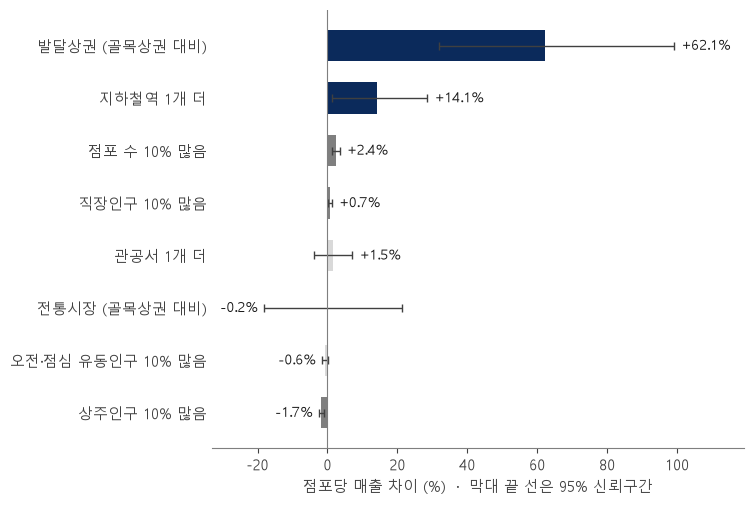

In [5]:
fig, ax = plt.subplots(figsize=FIG_SIZE['effects'])

y = np.arange(len(eff))
colors = []
for i, sig in enumerate(eff['유의']):
    if i in [0, 1]:        # 장표 제목이 말하는 두 요인(발달상권, 지하철역)만 강조색
        colors.append(ACCENT)
    elif sig:              # 나머지 유의한 요인은 회색
        colors.append(MID)
    else:                  # 유의하지 않은 요인은 아주 연한 회색
        colors.append(PALE)

# 신뢰구간 길이 = 효과에서 하한까지, 효과에서 상한까지
err_low = eff['효과_%'] - eff['하한_%']
err_high = eff['상한_%'] - eff['효과_%']

ax.barh(y, eff['효과_%'], color=colors, height=0.6)
ax.errorbar(eff['효과_%'], y, xerr=[err_low, err_high], fmt='none', ecolor=DARK, capsize=3, linewidth=1)
ax.axvline(0, color=MID, linewidth=0.8)

for i, v in enumerate(eff['효과_%']):
    # 양수는 신뢰구간 오른쪽 끝 바깥에, 음수는 왼쪽 끝 바깥에 숫자를 씀
    if v >= 0:
        ax.text(eff['상한_%'][i] + 2, i, f'{v:+.1f}%', va='center', ha='left', fontsize=10, color='#1A1A1A')
    else:
        ax.text(eff['하한_%'][i] - 2, i, f'{v:+.1f}%', va='center', ha='right', fontsize=10, color='#1A1A1A')

ax.set_yticks(y)
ax.set_yticklabels(eff['항목'])
ax.invert_yaxis()
ax.set_xlabel('점포당 매출 차이 (%)  ·  막대 끝 선은 95% 신뢰구간')
ax.set_xlim(eff['하한_%'].min() - 15, eff['상한_%'].max() + 20)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0)

fig.tight_layout()
save(fig, 'fig_effects')
plt.show()

#### 코드 읽기
- `plt.subplots(figsize=...)`: 그림(fig)과 축(ax)을 같이 만듭니다. 이번에는 축에 직접 그리는 방식(`ax.barh`)을 씁니다. 여러 설정을 한 축에 차례로 하기 편합니다.
- `colors = []` 다음 for문: 막대마다 색을 정합니다. 장표 제목에 나오는 두 요인(0번, 1번)은 강조색, 나머지 중 유의한 요인은 회색, 유의하지 않은 요인은 아주 연한 회색입니다.
- `ax.errorbar(..., xerr=[err_low, err_high], fmt='none')`: 막대 끝에 신뢰구간 선을 긋습니다. `xerr`에 왼쪽 길이와 오른쪽 길이를 따로 줍니다. `fmt='none'`이라 점은 안 찍고 선만 그립니다.
- `ax.axvline(0, ...)`: 0 위치에 세로선을 긋습니다. 선 왼쪽은 낮아지는 요인, 오른쪽은 높아지는 요인입니다.
- `for i, v in enumerate(...)`: 막대마다 숫자를 적습니다. 신뢰구간 선과 겹치지 않게 선 끝 바깥에 둡니다. `f'{v:+.1f}%'`의 `+`는 양수에도 + 기호를 붙이라는 뜻입니다.
- `ax.invert_yaxis()`: 리스트 첫 항목이 맨 위에 오게 합니다.
- `fig.tight_layout()`: 글자가 잘리지 않게 여백을 맞춥니다. 저장하기 전에 해야 저장된 그림에도 적용됩니다.

04 노트북과 같은 R²(0.261)가 나와서 같은 회귀를 다시 돌린 게 맞습니다. 유의한 요인은 발달상권 +62.1%, 지하철역 1개 +14.1%, 점포 수 10% +2.4%, 직장인구 10% +0.7%, 상주인구 10% -1.7%입니다.

발달상권은 95% 신뢰구간이 +32%~+99%, 지하철역은 +1%~+29%로 폭이 넓습니다. 그래서 장표에는 "62%", "14%" 대신 "약 60%", "약 14%"로 적고 각주에 신뢰구간을 남겼습니다. 점추정값 하나만 적으면 실제보다 정확한 숫자처럼 보이기 때문입니다.

## 2. 장표 5: 프랜차이즈 비중

처음 기준으로 뽑혔던 3곳과 최종 후보 3곳의 프랜차이즈 비중(최근 4분기 평균)을 서울 중앙값과 비교합니다.

In [6]:
cand = pd.read_sql('SELECT 상권_코드_명, 프랜차이즈_비중, 프랜차이즈_중앙값, 직장인구, 점포_수, 순위 FROM 후보_지표', engine)
fr_median = cand['프랜차이즈_중앙값'].iloc[0]

first = ['시청역_8번', '삼성역', '서울역']          # 처음 기준(③ 줄지 않음, ④ 없음)으로 뽑혔던 3곳
final = ['을지로3가역', '강남구청역', '서초역']      # 최종 후보

fr = cand[cand['상권_코드_명'].isin(first + final)].set_index('상권_코드_명')
fr = fr.loc[first + final, ['프랜차이즈_비중']]
fr['중앙값의_몇_배'] = fr['프랜차이즈_비중'] / fr_median

print('서울 중앙값:', round(fr_median * 100, 1), '%')
fr.round(3)

서울 중앙값: 21.8 %


,프랜차이즈_비중,중앙값의_몇_배
상권_코드_명,,
시청역_8번,0.335,1.540
삼성역,0.328,1.504
서울역,0.431,1.978
을지로3가역,0.187,0.860
강남구청역,0.171,0.786
서초역,0.216,0.990


#### 코드 읽기
- `fr_median = cand['프랜차이즈_중앙값'].iloc[0]`: 06 노트북의 SQL에서 계산한 중앙값입니다. 모든 줄에 같은 값이 붙어 있어서 첫 줄만 봅니다.
- `cand[cand['상권_코드_명'].isin(first + final)]`: 리스트 두 개를 `+`로 이어 붙여 여섯 곳만 남깁니다.
- `.set_index('상권_코드_명')`: 상권 이름을 인덱스로 만들어서 다음 줄의 `.loc[이름 리스트]`로 원하는 순서대로 꺼낼 수 있게 합니다.

저장: ../reports/figures/fig_franchise.png


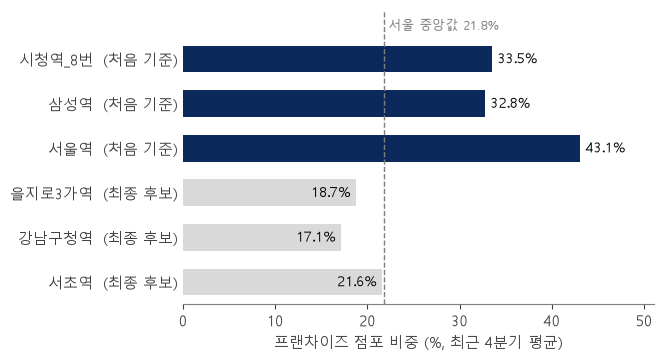

In [7]:
fig, ax = plt.subplots(figsize=FIG_SIZE['franchise'])

values = fr['프랜차이즈_비중'] * 100
colors = [ACCENT if name in first else PALE for name in fr.index]
y = np.arange(len(fr))

ax.barh(y, values, color=colors, height=0.6)
ax.axvline(fr_median * 100, color=MID, linestyle='--', linewidth=1)
ax.text(fr_median * 100 + 0.5, -0.75, f'서울 중앙값 {fr_median * 100:.1f}%', color=MID, fontsize=9, va='center')

for i, (name, v) in enumerate(zip(fr.index, values)):
    if name in first:
        ax.text(v + 0.6, i, f'{v:.1f}%', va='center', fontsize=10)              # 막대 오른쪽 바깥
    else:
        ax.text(v - 0.6, i, f'{v:.1f}%', va='center', ha='right', fontsize=10)  # 막대 안쪽 끝 (중앙값 점선과 안 겹치게)

labels = [name + ('  (처음 기준)' if name in first else '  (최종 후보)') for name in fr.index]
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_ylim(len(fr) - 0.5, -1.1)    # y축을 뒤집으면서 맨 위에 중앙값 글씨가 들어갈 자리를 남김
ax.set_xlim(0, values.max() + 8)
ax.set_xlabel('프랜차이즈 점포 비중 (%, 최근 4분기 평균)')
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0)

fig.tight_layout()
save(fig, 'fig_franchise')
plt.show()

#### 코드 읽기
- `colors = [ACCENT if name in first else PALE ...]`: 처음 기준 3곳만 강조색(남색)으로 칠하고 나머지는 연한 회색으로 둡니다. 이 장표에서 짚을 곳이 그 3곳이라 강조색을 한 무리에만 씁니다.
- `ax.axvline(..., linestyle='--')`: 서울 중앙값 위치에 점선을 긋습니다.
- `ax.text(...)`: 점선 옆에 "서울 중앙값"이라고 적습니다. y 위치 -0.75는 맨 위 막대(0번)보다 위쪽입니다.
- `ax.set_ylim(len(fr) - 0.5, -1.1)`: 범위를 큰 값 → 작은 값 순서로 주면 y축이 뒤집혀서 첫 상권이 맨 위에 옵니다. 위쪽 끝을 -1.1까지 늘려 중앙값 글씨 자리를 만들었습니다.
- 숫자 위치: 최종 후보 3곳은 막대 끝이 중앙값 점선 바로 옆이라 숫자를 막대 밖에 쓰면 점선과 겹칩니다. 그래서 최종 후보는 막대 안쪽 끝에 오른쪽 정렬(`ha='right'`)로 쓰고 처음 기준 3곳만 막대 밖에 씁니다. `zip(fr.index, values)`는 상권 이름과 값을 짝지어 하나씩 꺼냅니다.
- `labels = [...]`: 상권 이름 뒤에 어느 그룹인지 붙입니다. 색만으로 구분하지 않고 글자로도 알 수 있게 하려는 것입니다.

처음 기준 3곳은 서울 중앙값(21.8%)의 1.50~1.98배이고 최종 후보 3곳은 모두 중앙값보다 낮습니다. 장표 제목에는 반올림해서 "1.5~2배"로 적었습니다. 서초역(21.6%)은 중앙값과 거의 같습니다.

## 3. 장표 6: 2년 전과 지금의 점포당 매출 순위

05 노트북의 H5 계산을 다시 합니다.

In [8]:
rows_all = pd.read_sql('SELECT 상권_코드, 기준_년분기_코드, 점포당_매출, 결제부족 FROM 분석_대상 '
                       'WHERE 기준_년분기_코드 IN (20242, 20262)', engine)

before = rows_all[(rows_all['기준_년분기_코드'] == 20242) & (rows_all['결제부족'] == 0)]
after = rows_all[(rows_all['기준_년분기_코드'] == 20262) & (rows_all['결제부족'] == 0)]
pair = before.merge(after, on='상권_코드', suffixes=('_전', '_후'))

pair['순위_전'] = pair['점포당_매출_전'].rank(ascending=False)
pair['순위_후'] = pair['점포당_매출_후'].rank(ascending=False)

rho, p = stats.spearmanr(pair['점포당_매출_전'], pair['점포당_매출_후'])

n = len(pair)
top_n = round(n * 0.1)
pair['상위10_전'] = pair['순위_전'] <= top_n
pair['상위10_후'] = pair['순위_후'] <= top_n
kept = (pair['상위10_전'] & pair['상위10_후']).sum()

print('상권 수:', n, '/ ρ =', round(rho, 3))
print('2024Q2 상위 10%', top_n, '곳 중 2026Q2에도 상위 10%:', kept, f'({kept / top_n:.0%})')

상권 수: 964 / ρ = 0.907
2024Q2 상위 10% 96 곳 중 2026Q2에도 상위 10%: 71 (74%)


#### 코드 읽기
- 05 노트북의 `make_pair`, `make_versions`를 함수 없이 풀어 썼습니다. 여기서는 기본 버전 하나만 필요해서입니다.
- `before`, `after`: 두 분기 각각 결제부족이 아닌 줄만 남깁니다. merge(inner join)하면 두 분기 모두 남은 상권만 남습니다.
- `kept = (A & B).sum()`: 2년 전에도 지금도 상위 10%인 상권 수입니다.
- `f'{kept / top_n:.0%}'`: 비율을 %로 보여 줍니다. `.0%`는 100을 곱하고 소수점 없이 % 기호를 붙이라는 뜻입니다.

저장: ../reports/figures/fig_rank.png


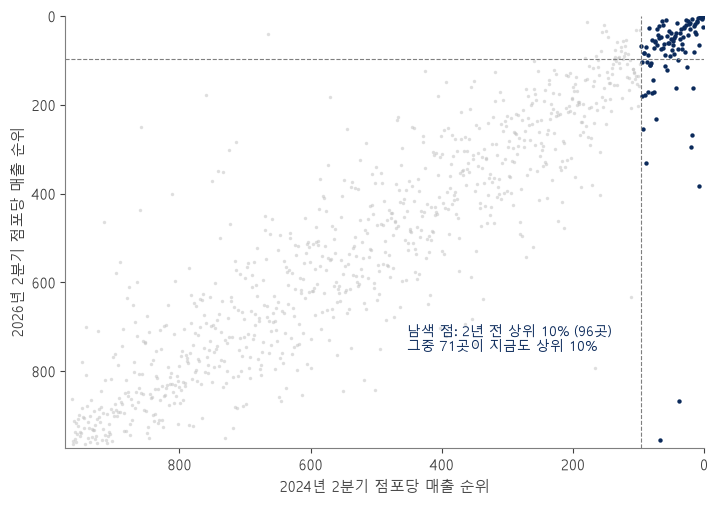

In [9]:
fig, ax = plt.subplots(figsize=FIG_SIZE['rank'])

others = pair[~pair['상위10_전']]
top_before = pair[pair['상위10_전']]

ax.scatter(others['순위_전'], others['순위_후'], s=6, color=LIGHT_GRAY, alpha=0.5, linewidths=0)
ax.scatter(top_before['순위_전'], top_before['순위_후'], s=10, color=ACCENT, linewidths=0)

# 상위 10% 경계선
ax.axvline(top_n, color=MID, linestyle='--', linewidth=0.8)
ax.axhline(top_n, color=MID, linestyle='--', linewidth=0.8)
ax.text(n * 0.47, n * 0.72, f'남색 점: 2년 전 상위 10% ({top_n}곳)\n그중 {kept}곳이 지금도 상위 10%', fontsize=10, color=ACCENT, ha='left', va='top')

ax.set_xlim(n + 10, 0)     # 순위 1이 오른쪽 위에 오도록 두 축을 뒤집음
ax.set_ylim(n + 10, 0)
ax.set_xlabel('2024년 2분기 점포당 매출 순위')
ax.set_ylabel('2026년 2분기 점포당 매출 순위')

fig.tight_layout()
save(fig, 'fig_rank')
plt.show()

#### 코드 읽기
- `~pair['상위10_전']`: `~`는 True/False를 뒤집습니다. 2년 전 상위 10%가 아닌 상권입니다.
- 산점도를 두 번 그립니다. 나머지 상권은 연한 회색, 2년 전 상위 10%는 강조색(남색)입니다. 진한 점들이 지금도 위쪽(상위권)에 모여 있는지 보는 그림입니다.
- `alpha=0.35`, `linewidths=0`: 점이 900개가 넘어서 반투명하게 하고 점 테두리 선을 없앴습니다.
- `ax.text(..., '...\n...')`: `\n`은 줄바꿈입니다. 점이 없는 오른쪽 아래 빈 곳에 설명을 둬서 점과 겹치지 않게 했습니다.
- `ax.set_xlim(n + 10, 0)`: 축 범위를 큰 값 → 0 순서로 주면 축이 뒤집힙니다. 순위 1등이 오른쪽 위에 와서 "위·오른쪽 = 좋음"으로 읽힙니다.

05 노트북과 같은 값(ρ = 0.907, 96곳 중 71곳)이 나왔습니다. 진한 점 대부분이 오른쪽 위에 모여 있고, 몇 개만 아래로 떨어져 있습니다. 떨어진 점들이 "상위권도 넷 중 하나는 밀려남"에 해당합니다.

## 4. 장표 7: 기준별로 남은 상권 수

In [10]:
top10 = cand[cand['순위'] <= 10]
final_count = ((top10['직장인구'] >= 10000) & (top10['점포_수'] >= 10)).sum()   # 임대료 2배 미만은 06에서 10곳 모두 충족 확인

funnel = pd.DataFrame({
    '단계': ['매출 공개 상권 (2026Q2)', '① 데이터 신뢰', '② 콘셉트 적합', '③ 점포당 매출 상승',
           '④ 프랜차이즈 비중 낮음', '⑤ 점포당 매출 상위', '⑥ 직장인구·점포 수·임대료'],
    '남은_상권_수': [
        len(cand),
        pd.read_sql('SELECT SUM(통과1_신뢰) FROM 후보_지표', engine).iloc[0, 0],
        pd.read_sql('SELECT SUM(통과2_콘셉트) FROM 후보_지표', engine).iloc[0, 0],
        pd.read_sql('SELECT SUM(통과3_추세) FROM 후보_지표', engine).iloc[0, 0],
        pd.read_sql('SELECT SUM(통과4_경쟁) FROM 후보_지표', engine).iloc[0, 0],
        len(top10),
        final_count,
    ],
})
funnel

,단계,남은_상권_수
0,매출 공개 상권 (2026Q2),1058
1,① 데이터 신뢰,974
2,② 콘셉트 적합,349
3,③ 점포당 매출 상승,195
4,④ 프랜차이즈 비중 낮음,95
5,⑤ 점포당 매출 상위,10
6,⑥ 직장인구·점포 수·임대료,3


#### 코드 읽기
- `final_count`: 상위 10곳 중 직장인구 1만 명 이상이고 점포 10개 이상인 곳의 수입니다. 임대료 조건(서울 평균 2배 미만)은 06 노트북에서 10곳 모두 통과한 걸 확인해서 여기서는 다시 계산하지 않았습니다(임대료는 손으로 맞춘 표라서).
- `pd.read_sql('SELECT SUM(...) ...').iloc[0, 0]`: SQL로 통과한 상권 수를 세고 결과 표의 첫 칸 값만 꺼냅니다.

findfont: Failed to find font weight bold, now using 400.


저장: ../reports/figures/fig_funnel.png


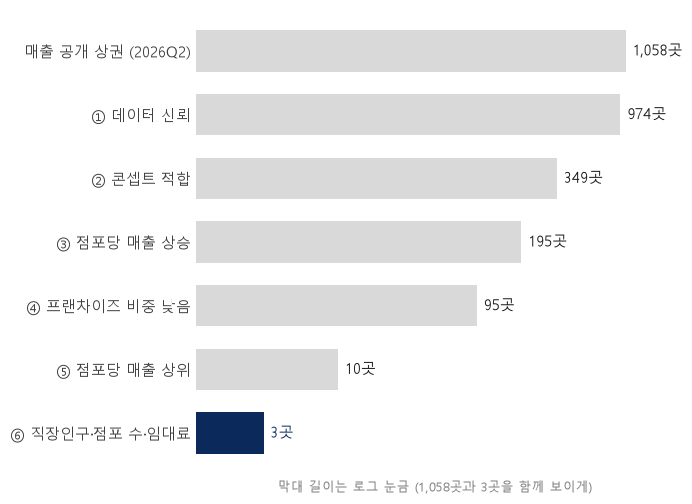

In [11]:
fig, ax = plt.subplots(figsize=FIG_SIZE['funnel'])

y = np.arange(len(funnel))
colors = [PALE] * (len(funnel) - 1) + [ACCENT]      # 마지막(최종 3곳)만 강조색
ax.barh(y, funnel['남은_상권_수'], color=colors, height=0.65)
ax.set_xscale('log')    # 1,058곳과 3곳을 한 그림에 보이게 로그 눈금으로

for i, v in enumerate(funnel['남은_상권_수']):
    ax.text(v * 1.12, i, f'{v:,}곳', va='center', fontsize=11, color=ACCENT if i == len(funnel) - 1 else '#1A1A1A',
            fontweight='bold' if i == len(funnel) - 1 else 'normal')

ax.set_yticks(y)
ax.set_yticklabels(funnel['단계'])
ax.invert_yaxis()
ax.set_xlim(1, funnel['남은_상권_수'].max() * 2.2)
ax.set_xticks([])
ax.minorticks_off()
ax.set_xlabel('막대 길이는 로그 눈금 (1,058곳과 3곳을 함께 보이게)', fontsize=9, color=MID)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='y', length=0)

fig.tight_layout()
save(fig, 'fig_funnel')
plt.show()

#### 코드 읽기
- `[PALE] * (len(funnel) - 1) + [ACCENT]`: 리스트에 `*`를 하면 같은 값이 반복됩니다. 앞의 단계들은 아주 연한 회색, 마지막 단계만 강조색이 됩니다.
- `f'{v:,}곳'`: `,`는 천 단위 쉼표를 넣으라는 뜻입니다(1058 → 1,058).
- `ax.set_xscale('log')`: 가로축을 로그 눈금으로 바꿉니다. 그냥 그리면 1,058곳 막대에 비해 10곳, 3곳 막대가 너무 짧아서 거의 안 보였습니다. 로그 눈금에서는 10배 차이가 같은 길이로 보여서 작은 값도 보입니다. 대신 막대 길이를 그대로 비교하면 안 되니 축 아래에 로그 눈금이라고 적었습니다.
- `v * 1.12`: 로그 눈금에서는 "몇 칸 오른쪽"보다 "몇 배 오른쪽"이 같은 간격으로 보여서, 숫자 위치도 값에 1.12를 곱해 정했습니다.
- `ax.set_xlim(1, ...)`: 로그 눈금은 0을 그릴 수 없어서 왼쪽 끝을 1로 둡니다.
- `ax.set_xticks([])`, `ax.minorticks_off()`: 막대 끝에 숫자를 적었으니 눈금은 지웁니다. 로그 축은 작은 보조 눈금도 생겨서 그것까지 끕니다.

## 5. 장표 8: 후보 위치

영역 데이터의 상권 중심 좌표로 후보 위치를 그립니다. 경계선 지도 파일은 따로 쓰지 않고, 분석 대상 상권 1,058곳을 연한 점으로 찍어서 서울 모양이 드러나게 했습니다.

In [12]:
geo = pd.read_sql('SELECT c.상권_코드_명, a.엑스좌표_값 AS x, a.와이좌표_값 AS y '
                  'FROM 후보_지표 c JOIN 원본_영역 a ON c.상권_코드 = a.상권_코드', engine)
geo = geo.set_index('상권_코드_명')

def dist_km(a, b):
    # 좌표 단위가 미터라서 두 점 사이 직선거리를 구하고 1000으로 나눔
    dx = geo.loc[a, 'x'] - geo.loc[b, 'x']
    dy = geo.loc[a, 'y'] - geo.loc[b, 'y']
    return (dx ** 2 + dy ** 2) ** 0.5 / 1000

pairs_km = [('을지로3가역', '시청역_8번'), ('을지로3가역', '서울역'), ('강남구청역', '삼성역'), ('서초역', '강남구청역')]
for a, b in pairs_km:
    print(f'{a} ↔ {b}: {dist_km(a, b):.1f} km')

을지로3가역 ↔ 시청역_8번: 1.6 km
을지로3가역 ↔ 서울역: 2.0 km
강남구청역 ↔ 삼성역: 2.2 km
서초역 ↔ 강남구청역: 4.0 km


#### 코드 읽기
- `원본_영역`의 `엑스좌표_값`, `와이좌표_값`은 상권 중심점의 좌표입니다. 값이 20만, 45만 정도인 평면 좌표(미터 단위)라서 위도·경도처럼 변환하지 않아도 거리를 바로 잴 수 있습니다.
- `def dist_km(a, b):`: 두 상권의 x 차이와 y 차이로 피타고라스 정리(√(dx² + dy²))를 써서 직선거리를 구합니다. `** 0.5`는 제곱근입니다.
- `f'{a} ↔ {b}: {dist_km(a, b):.1f} km'`: `.1f`는 소수점 한 자리까지 보여 주라는 뜻입니다.

findfont: Failed to find font weight bold, now using 400.


저장: ../reports/figures/fig_map.png


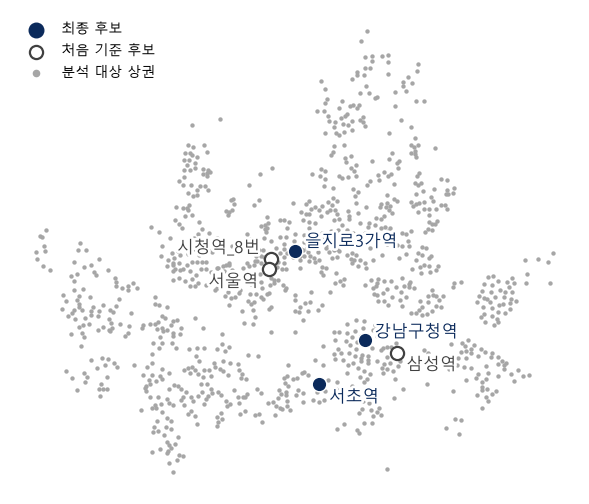

In [13]:
fig, ax = plt.subplots(figsize=FIG_SIZE['map'])

ax.scatter(geo['x'], geo['y'], s=10, color='#A6A6A6', linewidths=0)   # 배경 점. 너무 연하면 서울 모양이 안 보여서 중간 회색으로
for name in first:
    ax.scatter(geo.loc[name, 'x'], geo.loc[name, 'y'], s=90, facecolors='white', edgecolors=DARK, linewidths=1.6, zorder=3)
for name in final:
    ax.scatter(geo.loc[name, 'x'], geo.loc[name, 'y'], s=110, color=ACCENT, edgecolors='white', linewidths=1, zorder=4)

# 이름이 겹치지 않게 점에서 얼마나 떨어뜨릴지 손으로 정함 (단위: 미터)
label_offset = {
    '을지로3가역': (600, 600),
    '강남구청역': (600, 500),
    '서초역': (600, -800),
    '시청역_8번': (-600, 700),
    '서울역': (-600, -800),
    '삼성역': (600, -700),
}
for name, (dx, dy) in label_offset.items():
    if name in final:
        color, weight = ACCENT, 'bold'
    else:
        color, weight = DARK, 'normal'
    ha = 'left' if dx > 0 else 'right'
    label = ax.text(geo.loc[name, 'x'] + dx, geo.loc[name, 'y'] + dy, name, color=color, fontsize=12,
                    fontweight=weight, ha=ha, va='center', zorder=5)
    # 글자 둘레에 흰 테두리를 둘러서 뒤의 회색 점과 겹쳐도 읽히게 함
    label.set_path_effects([patheffects.withStroke(linewidth=4, foreground='white')])

# 범례용으로 빈 점을 하나씩 찍음
ax.scatter([], [], s=110, color=ACCENT, label='최종 후보')
ax.scatter([], [], s=90, facecolors='white', edgecolors=DARK, linewidths=1.6, label='처음 기준 후보')
ax.scatter([], [], s=20, color='#A6A6A6', label='분석 대상 상권')
legend = ax.legend(loc='upper left', frameon=True, fontsize=10)   # 서울 북서쪽 바깥의 빈 곳. 아래쪽은 점과 겹침
legend.get_frame().set_facecolor('white')     # 범례 뒤 점이 비치지 않게 흰 바탕
legend.get_frame().set_edgecolor('white')
legend.set_zorder(6)

ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

fig.tight_layout()
save(fig, 'fig_map')
plt.show()

#### 코드 읽기
- 점을 세 번 나눠 찍습니다. 전체 상권은 중간 회색(`#A6A6A6`, 처음에는 아주 연한 회색이었는데 장표에서 서울 모양이 잘 안 보여서 진하게 바꿈), 처음 기준 후보는 속이 빈 회색 동그라미, 최종 후보는 강조색(남색)에 흰 테두리를 둘러 회색 점 위에서도 잘 보이게 했습니다. `zorder`가 클수록 위에 그려져서 후보 점이 회색 점에 가려지지 않습니다.
- `facecolors='white', edgecolors=DARK`: 속은 흰색, 테두리만 회색인 점입니다.
- `label_offset`: 상권 이름을 점에서 조금 떨어진 곳에 쓰려고 상권마다 (x 이동, y 이동)을 정했습니다. 시청역_8번과 서울역은 600m 정도밖에 안 떨어져 있어서 이름을 위아래로 나눴습니다.
- `label.set_path_effects([patheffects.withStroke(...)])`: 글자 둘레에 흰 테두리(굵기 4)를 그립니다. 배경 점이 진해지면서 이름과 겹쳐 읽기 어려워서 넣었습니다.
- `loc='upper left'`: 범례를 그림 왼쪽 위에 둡니다. 처음에는 왼쪽 아래에 뒀는데 서울 남서쪽 점들과 겹쳐서, 점이 하나도 없는 왼쪽 위로 옮겼습니다.
- `legend.get_frame()...`: 범례 상자를 흰 바탕으로 칠합니다. 테두리 선도 흰색이라 상자처럼 보이지는 않습니다.
- `ax.scatter([], [], ..., label=...)`: 데이터 없이 범례에만 나올 점을 만듭니다. 위에서 점을 여러 번 나눠 찍어서 범례를 이렇게 따로 만드는 게 간단합니다.
- `ax.set_aspect('equal')`: 가로 1m와 세로 1m가 같은 길이로 보이게 합니다. 이걸 안 하면 지도가 그림 비율에 맞춰 찌그러집니다.
- `set_xticks([])`: 좌표 숫자는 읽을 필요가 없어서 눈금을 지웁니다.

최종 후보는 처음 기준 후보와 같은 권역에 있습니다. 을지로3가역은 시청역_8번에서 1.6km, 강남구청역은 삼성역에서 2.2km 떨어져 있습니다. 서초역은 강남구청역에서 4.0km 떨어진 별도 상권입니다. 오피스가 모인 권역은 그대로 두고 그 안에서 대형 프랜차이즈가 적은 상권으로 옮긴 결과입니다.

## 6. 장표별 숫자 모음

장표에 적은 숫자가 어디서 나왔는지 한눈에 보려고 정리했습니다. 장표 번호는 PowerPoint 화면 오른쪽 아래의 쪽 번호입니다.

In [14]:
# 서울 기준값: 후보와 같은 기준(최근 4분기 평균)으로 맞춤. ①을 통과한 상권 사이의 중앙값
seoul_4q = pd.read_sql('SELECT 최근_점포당_매출 FROM 후보_지표 WHERE 통과1_신뢰 = 1', engine)
seoul_4q_median = seoul_4q['최근_점포당_매출'].median()
final_sales = pd.read_sql('SELECT 상권_코드_명, 최근_점포당_매출 FROM 후보_지표', engine).set_index('상권_코드_명')
ratios = final_sales.loc[final, '최근_점포당_매출'] / seoul_4q_median

rows = [
    ('2·9', '서울 점포당 분기 매출 중앙값 (최근 4분기, 만 원)', round(seoul_4q_median / 10000), '07'),
    ('9·10', '후보 / 서울 중앙값 (최소, 배)', round(ratios.min(), 1), '07'),
    ('9·10', '후보 / 서울 중앙값 (최대, 배)', round(ratios.max(), 1), '07'),
    ('4', '발달상권 효과 95% 신뢰구간 (%)', f"{eff.loc[0, '하한_%']:.0f} ~ {eff.loc[0, '상한_%']:.0f}", '07'),
    ('4', '지하철역 효과 95% 신뢰구간 (%)', f"{eff.loc[1, '하한_%']:.0f} ~ {eff.loc[1, '상한_%']:.0f}", '07'),
    ('8', '을지로3가역 ↔ 시청역_8번 (km)', round(dist_km('을지로3가역', '시청역_8번'), 1), '07'),
    ('8', '강남구청역 ↔ 삼성역 (km)', round(dist_km('강남구청역', '삼성역'), 1), '07'),
    ('3', 'H1 직장인구 상관계수', 0.368, '04'),
    ('3', 'H5 순위상관 ρ', round(rho, 3), '05·07'),
    ('4', '회귀 R²', round(model.rsquared, 3), '04·07'),
    ('4', '발달상권 효과 (%)', round(eff.loc[0, '효과_%'], 1), '07'),
    ('4', '지하철역 1개 효과 (%)', round(eff.loc[1, '효과_%'], 1), '07'),
    ('4', '점포 수 10% 효과 (%)', round(eff.loc[2, '효과_%'], 1), '07'),
    ('5', '프랜차이즈 중앙값 (%)', round(fr_median * 100, 1), '06·07'),
    ('5', '처음 기준 3곳 / 중앙값 (최소, 배)', round(fr.loc[first, '중앙값의_몇_배'].min(), 2), '07'),
    ('5', '처음 기준 3곳 / 중앙값 (최대, 배)', round(fr.loc[first, '중앙값의_몇_배'].max(), 2), '07'),
    ('6', '상위 10% 유지 비율 (%)', round(kept / top_n * 100), '05·07'),
    ('7', '최종 후보 수', final_count, '06·07'),
]
pd.DataFrame(rows, columns=['장표', '항목', '값', '노트북'])

,장표,항목,값,노트북
0,2·9,"서울 점포당 분기 매출 중앙값 (최근 4분기, 만 원)",1519,07
1,9·10,"후보 / 서울 중앙값 (최소, 배)",3.3,07
2,9·10,"후보 / 서울 중앙값 (최대, 배)",4.5,07
3,4,발달상권 효과 95% 신뢰구간 (%),32 ~ 99,07
4,4,지하철역 효과 95% 신뢰구간 (%),1 ~ 29,07
5,8,을지로3가역 ↔ 시청역_8번 (km),1.6,07
6,8,강남구청역 ↔ 삼성역 (km),2.2,07
7,3,H1 직장인구 상관계수,0.368,04
8,3,H5 순위상관 ρ,0.907,05·07
9,4,회귀 R²,0.261,04·07


#### 코드 읽기
- `seoul_4q_median`: 장표에서 후보와 비교하는 서울 중앙값입니다. 후보 매출이 최근 4분기 평균이라서 서울 중앙값도 같은 기준(①을 통과한 974곳의 최근 4분기 평균)으로 구했습니다. 처음에는 2026년 2분기 한 분기 중앙값(1,483만 원)과 비교했는데 기준이 달라서 바꿨습니다.
- `ratios`: 후보 3곳의 점포당 매출이 서울 중앙값의 몇 배인지입니다. `final` 리스트 순서대로 꺼냅니다.
- `rows`: (장표 번호, 항목, 값, 나온 노트북)을 튜플로 묶은 리스트입니다. `pd.DataFrame(rows, columns=[...])`로 표를 만들 때 컬럼 이름을 따로 줍니다.
- H1 상관계수(0.368)는 04 노트북 결과를 옮겨 적었습니다. 나머지는 이 노트북에서 다시 계산한 값입니다.

## 정리

- 차트 5개를 `reports/figures/`에 저장했습니다. 크기는 장표의 그림 칸 크기와 같습니다.
- 장표의 숫자는 04~06 노트북 결과와 같은지 다시 계산해서 확인했습니다.
- 후보와 비교하는 서울 중앙값은 후보와 같은 기준(최근 4분기 평균)인 1,519만 원으로 맞췄습니다.
- 장표는 `reports/deck_spec.json`(장표 내용)을 슬라이드 스킬로 빌드해서 만듭니다. 차트를 다시 그리면 덱도 다시 빌드해야 반영됩니다.

## 확인 질문

<details>
<summary>1. 차트 크기를 장표의 그림 칸 크기에 맞춘 이유는?</summary>

슬라이드 스킬은 그림을 칸 크기에 맞춰 늘립니다. 그림 비율이 칸과 다르면 가로나 세로로 찌그러집니다. 같은 크기로 그리면 늘어나지 않고 글자 크기도 의도한 대로 보입니다.
</details>

<details>
<summary>2. 신뢰구간도 계수처럼 %로 바꾼 이유는?</summary>

막대(효과)는 %인데 신뢰구간이 계수 단위 그대로면 같은 축에 그릴 수 없습니다. 계수에 쓴 변환(1.1^b − 1 또는 exp(b) − 1)을 신뢰구간 양 끝에도 똑같이 적용해야 단위가 맞습니다.
</details>

<details>
<summary>3. 한 차트에 강조색을 한 곳에만 쓰는 이유는?</summary>

색이 많으면 어디를 봐야 할지 흐려집니다. 프랜차이즈 차트에서는 장표 제목이 말하는 "처음 기준 3곳"만 남색으로 칠하고 나머지는 연한 회색으로 둬서 눈이 바로 그쪽으로 가게 했습니다. 이 보고서는 장표 전체에서도 회색 단계와 남색 하나만 씁니다.
</details>